# DSCI 552, Homework 0

Name: Zhengshu Zhang

GitHub username: forestzs

USC ID: 4664738582

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

## Section 4. Pandas

### 4(b) Read Salaries.csv into a dataframe with read_csv

In [2]:
path = "../data/salaries/Salaries.csv"

sal = pd.read_csv(path)
print(sal.shape)
sal.head()

(25575, 5)


,yearID,teamID,lgID,playerID,salary
0,1985,ATL,NL,barkele01,870000
1,1985,ATL,NL,bedrost01,550000
2,1985,ATL,NL,benedbr01,545000
3,1985,ATL,NL,campri01,633333
4,1985,ATL,NL,ceronri01,625000


### 4(c) Read the file again with playerID as the index, the first row as the header, and the second row skipped

In [3]:
df = pd.read_csv(path, header=0, index_col="playerID", skiprows=[1])
print(df.shape)
df.head()

(25574, 4)


,yearID,teamID,lgID,salary
playerID,,,,
bedrost01,1985,ATL,NL,550000
benedbr01,1985,ATL,NL,545000
campri01,1985,ATL,NL,633333
ceronri01,1985,ATL,NL,625000
chambch01,1985,ATL,NL,800000


Because the first row of the file is consumed as the header, skipping the second row removes the first data record: barkele01, 1985, ATL, NL, salary 870000. That leaves 25574 rows against the 25575 read in 4(b). The player is not removed from the dataset, since barkele01 still appears in four later records; only the 1985 row is lost.

### 4(d) Ids of the players registered in ATL and HOU whose salary is higher than one million

In [4]:
big = df[df["teamID"].isin(["ATL", "HOU"]) & (df["salary"] > 1000000)]
ids = big.index.unique()

print(big.shape[0], len(ids))
print(ids[:10].tolist())
big.head(10)

595 242
['hornebo01', 'murphda05', 'suttebr01', 'ryanno01', 'griffke01', 'smithda02', 'clancji01', 'davisgl01', 'ramirra01', 'scottmi03']


,yearID,teamID,lgID,salary
playerID,,,,
hornebo01,1985,ATL,NL,1500000
murphda05,1985,ATL,NL,1625000
suttebr01,1985,ATL,NL,1354167
ryanno01,1985,HOU,NL,1350000
hornebo01,1986,ATL,NL,1800000
murphda05,1986,ATL,NL,1825000
suttebr01,1986,ATL,NL,1729167
ryanno01,1986,HOU,NL,1125000
griffke01,1987,ATL,NL,1150000


The condition matches 595 salary records, which belong to 242 distinct player ids. The two numbers differ because a player earning above the threshold for several seasons contributes one row per season.

### 4(e) Use describe() for the standard deviation, quartiles, median, mean, maximum and minimum of the salary in team ATL

In [5]:
atl_salary = df[df["teamID"] == "ATL"]["salary"]
atl_salary.describe()

count    8.850000e+02
mean     2.207749e+06
std      3.434320e+06
min      6.000000e+04
25%      3.000000e+05
50%      6.000000e+05
75%      2.400000e+06
max      1.606180e+07
Name: salary, dtype: float64

In the output above the `std` row is the standard deviation, `25%` is the first quartile, `50%` is the median, `75%` is the third quartile, and `mean`, `max` and `min` give the remaining three statistics directly; `count` is not one of the seven asked for. For ATL the standard deviation is 3434319.61, the first quartile 300000, the median 600000, the third quartile 2400000, the mean 2207749.19, the maximum 16061802 and the minimum 60000, over 885 salary records.

### 4(f) Dictionary whose keys are the dataframe headers and whose values are lists of the corresponding data

In [6]:
# iterrows() is used because the question asks for it, although to_dict("list") is the direct way
cols = {name: [] for name in df.columns}
for _, row in df.iterrows():
    for name in cols:
        cols[name].append(row[name])

print(list(cols))
print({name: len(values) for name, values in cols.items()})

['yearID', 'teamID', 'lgID', 'salary']
{'yearID': 25574, 'teamID': 25574, 'lgID': 25574, 'salary': 25574}


playerID is the index of this dataframe rather than one of its columns, so the four remaining headers become the keys. Each value list holds 25574 entries, which matches the row count of the 4(c) dataframe.

### 4(g) Dataframe built from the 4(f) dictionary, with the header changed to "a", "b", "c", ...

In [7]:
renamed = pd.DataFrame(cols)
renamed.columns = [chr(ord("a") + i) for i in range(renamed.shape[1])]

print(renamed.shape)
renamed.head()

(25574, 4)


,a,b,c,d
0,1985,ATL,NL,550000
1,1985,ATL,NL,545000
2,1985,ATL,NL,633333
3,1985,ATL,NL,625000
4,1985,ATL,NL,800000


The handout writes pd.DataFrameRead and refers back to part (e), which are typos for pd.DataFrame and part (f). Assigning to `columns` renames in position, so the original order is kept and a, b, c and d stand for yearID, teamID, lgID and salary.

## Section 9. Seaborn

### 9(b) Create a dataframe and plot it with seaborn

The file holds 25574 individual salary records, which is far too many for a readable categorical plot, so this part aggregates rather than samples: the mean salary of every team in the 2015 season, giving one bar per team.

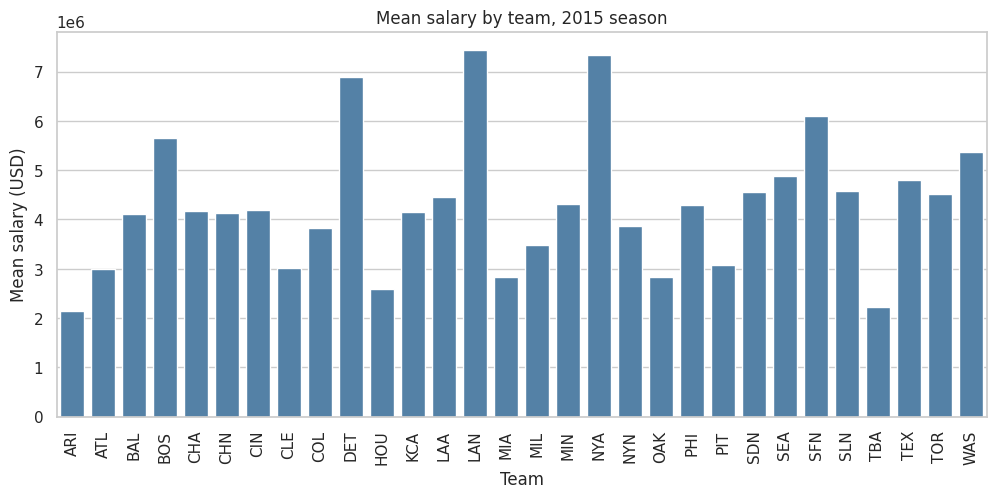

In [8]:
mean_2015 = df[df["yearID"] == 2015].groupby("teamID", as_index=False)["salary"].mean()

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=mean_2015, x="teamID", y="salary", color="steelblue")
ax.set_title("Mean salary by team, 2015 season")
ax.set_xlabel("Team")
ax.set_ylabel("Mean salary (USD)")
plt.xticks(rotation=90)
plt.show()

### 9(c) Statistical estimation with lmplot, catplot and relplot

Five teams are kept for the first two plots: ATL and HOU carry over from Section 4, and BOS, LAN and NYA are added as large-market clubs for contrast. The lmplot uses the mean salary of each of those teams in each season from 1985 to 2015, so one point is one team-season. The catplot uses the individual salaries of the same five teams in the 2015 season only, so that the bars estimate a single-season mean. The relplot uses every row in the file, aggregated to the mean salary per league per season, so nothing is dropped there.

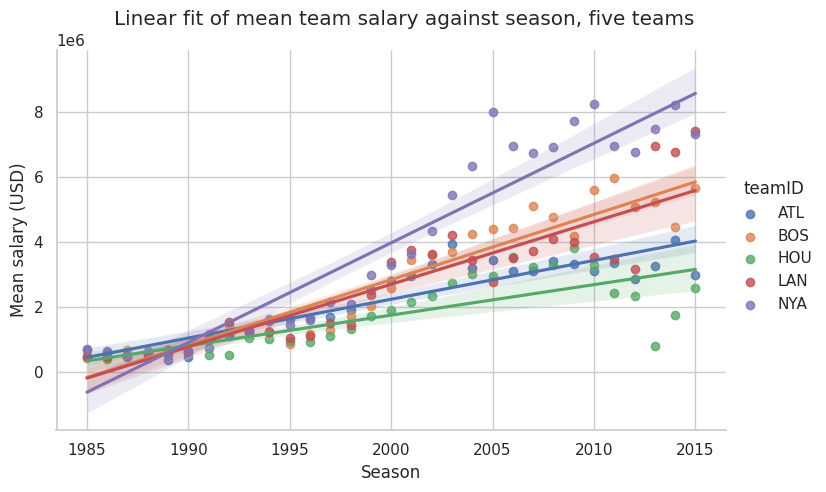

In [9]:
teams = ["ATL", "BOS", "HOU", "LAN", "NYA"]
yearly = df[df["teamID"].isin(teams)].groupby(["yearID", "teamID"], as_index=False)["salary"].mean()

g = sns.lmplot(data=yearly, x="yearID", y="salary", hue="teamID", height=5, aspect=1.5)
g.set_axis_labels("Season", "Mean salary (USD)")
g.figure.suptitle("Linear fit of mean team salary against season, five teams")
g.figure.subplots_adjust(top=0.90)
plt.show()

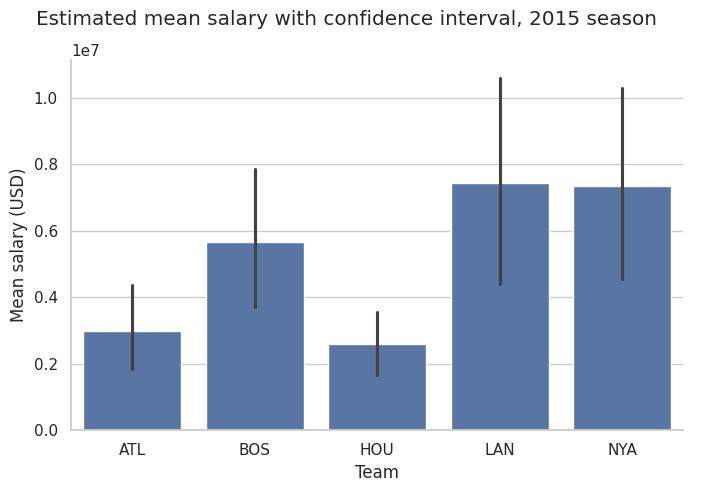

In [10]:
season_2015 = df[(df["yearID"] == 2015) & (df["teamID"].isin(teams))]

g = sns.catplot(data=season_2015, x="teamID", y="salary", kind="bar", height=5, aspect=1.4)
g.set_axis_labels("Team", "Mean salary (USD)")
g.figure.suptitle("Estimated mean salary with confidence interval, 2015 season")
g.figure.subplots_adjust(top=0.88)
plt.show()

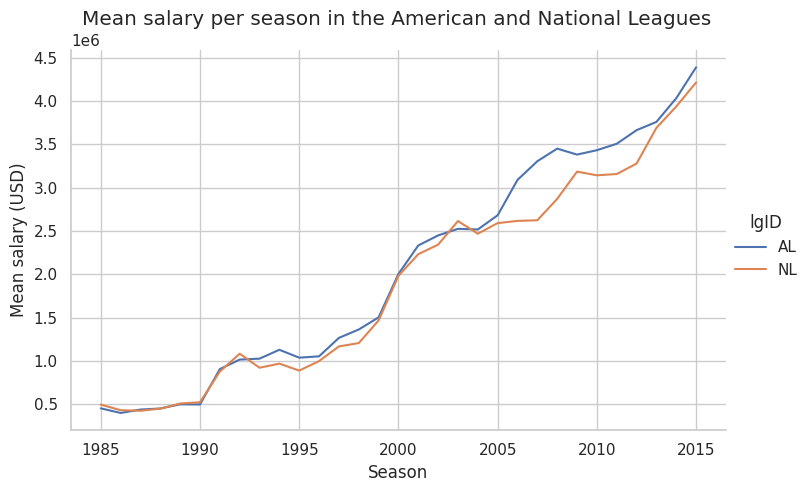

In [11]:
league = df.groupby(["yearID", "lgID"], as_index=False)["salary"].mean()

g = sns.relplot(data=league, x="yearID", y="salary", hue="lgID", kind="line", height=5, aspect=1.5)
g.set_axis_labels("Season", "Mean salary (USD)")
g.figure.suptitle("Mean salary per season in the American and National Leagues")
g.figure.subplots_adjust(top=0.90)
plt.show()

### 9(d) Axis level function: boxplot

The same five teams are used, but here every individual salary from 1985 to 2015 is kept, since a boxplot summarises the distribution itself and does not need aggregating. Salaries run from tens of thousands to tens of millions, so the vertical axis is logarithmic.

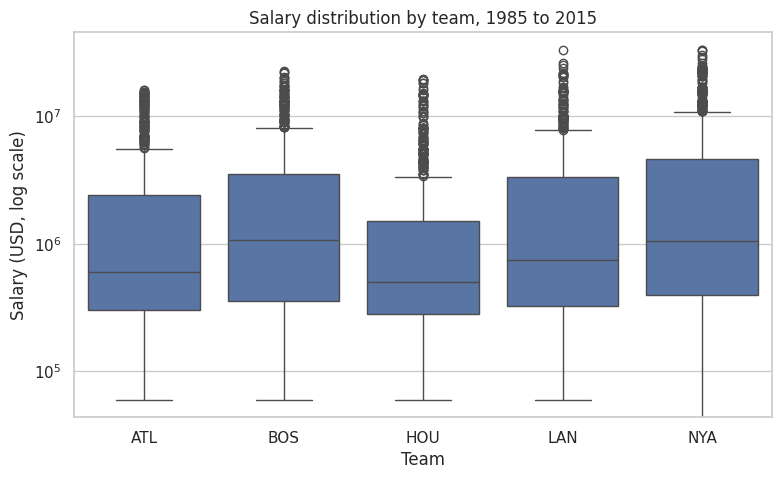

In [12]:
five = df[df["teamID"].isin(teams)]

plt.figure(figsize=(9, 5))
ax = sns.boxplot(data=five, x="teamID", y="salary")
ax.set_yscale("log")
ax.set_title("Salary distribution by team, 1985 to 2015")
ax.set_xlabel("Team")
ax.set_ylabel("Salary (USD, log scale)")
plt.show()

### 9(e) Visualise the structure of the dataset with pairplot and jointplot

The pairplot needs one numeric column per variable, so the yearly table from 9(c) is pivoted into one column of mean salary per team, with the season as the row. The jointplot then takes a single team, NYA, and looks at its mean salary against the season.

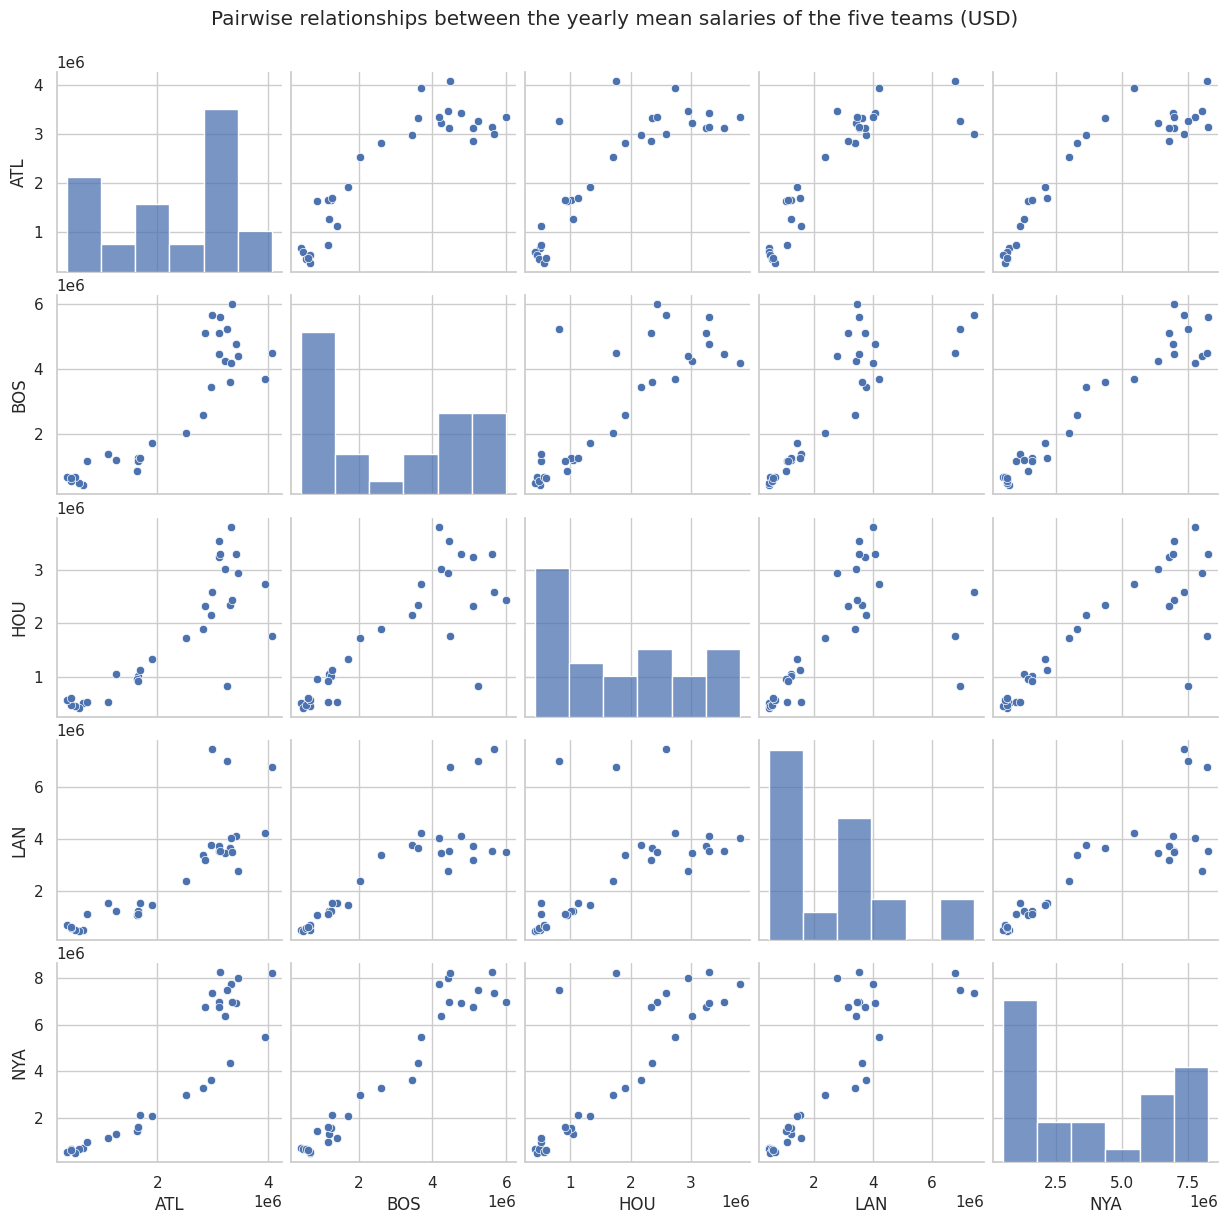

In [13]:
wide = yearly.pivot(index="yearID", columns="teamID", values="salary")

g = sns.pairplot(wide)
g.figure.suptitle("Pairwise relationships between the yearly mean salaries of the five teams (USD)")
g.figure.subplots_adjust(top=0.93)
plt.show()

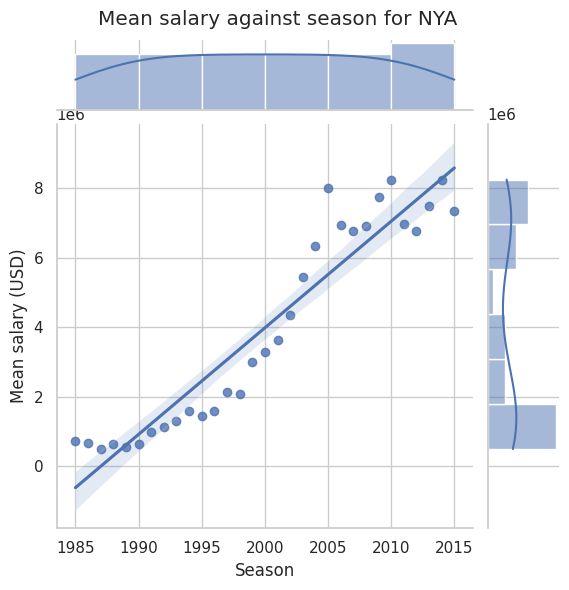

In [14]:
g = sns.jointplot(data=yearly[yearly["teamID"] == "NYA"], x="yearID", y="salary", kind="reg", height=6)
g.set_axis_labels("Season", "Mean salary (USD)")
g.figure.suptitle("Mean salary against season for NYA")
g.figure.subplots_adjust(top=0.93)
plt.show()

The five teams move together across the pairplot, which reflects the league-wide rise in salaries over the period rather than any relationship between the clubs. The jointplot shows the same upward trend for NYA, with the marginal histograms indicating that the higher mean salaries are concentrated in the later seasons.

## Section 5. Numpy

In [15]:
import numpy as np

### 5(a) Build a 2-dimensional Python list and convert it to a numpy array

In [16]:
grid = [[1, 2, 3, 4],
        [5, 6, 7, 8],
        [9, 10, 11, 12]]

a = np.array(grid)
a

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

### 5(b) The ndim, shape, size, dtype, itemsize and data attributes

In [17]:
print(a.ndim)
print(a.shape)
print(a.size)
print(a.dtype)
print(a.itemsize)
print(a.data)

2
(3, 4)
12
int64
8


`ndim` reports the number of axes, `shape` the length of each axis, `size` the total number of elements, `dtype` the type of a single element, `itemsize` the number of bytes one element occupies, and `data` the buffer object that holds the raw memory. For this array they are 2, (3, 4), 12, int64, 8, and a memoryview whose address changes from run to run.

### 5(c) Dimension of ndarray objects with reshape() and flatten()

In [18]:
r = a.reshape(4, 3)
f = a.flatten()

print(r)
print(f)
print(r.base is a, f.base is None)

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
[ 1  2  3  4  5  6  7  8  9 10 11 12]
True True


reshape() keeps the same elements and only reinterprets the shape, returning a view onto the original buffer whenever the layout allows it, which is why `r.base is a` is True. flatten() always returns a new one-dimensional array with its own memory, so its base is None and writing into it cannot affect `a`.

### 5(d) Slicing a 1-D array and a 2-D array

In [19]:
v = np.arange(10)
print(v[2:7])
print(v[::3])

print(a[1])
print(a[:, 2])
print(a[0:2, 1:3])

[2 3 4 5 6]
[0 3 6 9]
[5 6 7 8]
[ 3  7 11]
[[2 3]
 [6 7]]


On the 1-D array the two slices take elements 2 to 6 and then every third element. On the 2-D array `a[1]` is the second row, `a[:, 2]` is the third column, and `a[0:2, 1:3]` is the sub-block of the first two rows crossed with the second and third columns.

In [20]:
b = a.copy()
sl = b[0:2, 1:3]
sl[0, 0] = 99
print(b)
print(sl.base is b)

cp = b[0:2, 1:3].copy()
cp[0, 0] = -1
print(b[0, 1], cp[0, 0])

[[ 1 99  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
True
99 -1


A basic slice returns a view rather than a copy: assigning into `sl` changes `b` at position [0, 1] as well, and `sl.base is b` is True. Taking `.copy()` of the same slice breaks that link, so writing -1 into `cp` leaves `b[0, 1]` at 99.

### 5(e) argmin, argmax, min, max, mean, sum, std, dot, square, sqrt, abs, exp, sign and mod

In [21]:
m = np.array([[3, -1, 4],
              [1, 5, -9]])

print(m.argmin(), m.argmax())
print(m.min(axis=0))
print(m.max(axis=1))
print(m.sum(axis=0))
print(m.mean(), m.sum(), m.min(), m.max(), m.std())

5 4
[ 1 -1 -9]
[4 5]
[ 4  4 -5]
0.5 3 -9 5 4.681523968396046


In [22]:
u = np.array([1, 2, 3])
w = np.array([4, 5, 6])

print(np.dot(u, w))
print(np.square(m))
print(np.abs(m))
print(np.sqrt(np.abs(m)))
print(np.exp(u))
print(np.sign(m))
print(np.mod(np.abs(m), 3))

32
[[ 9  1 16]
 [ 1 25 81]]
[[3 1 4]
 [1 5 9]]
[[1.73205081 1.         2.        ]
 [1.         2.23606798 3.        ]]
[ 2.71828183  7.3890561  20.08553692]
[[ 1 -1  1]
 [ 1  1 -1]]
[[0 1 1]
 [1 2 0]]


For a 2-D array `axis=0` collapses down the rows and leaves one value per column, while `axis=1` collapses across the columns and leaves one value per row. So `m.min(axis=0)` gives [1, -1, -9], the smallest entry of each of the three columns, and `m.max(axis=1)` gives [4, 5], the largest entry of each of the two rows. Called without an axis, argmin and argmax report positions in the flattened array, which is why the minimum -9 is reported as index 5.

### 5(f) arange, ones, zeros, eye, linspace and concatenate

In [23]:
print(np.arange(0, 10, 2))
print(np.ones((2, 3)))
print(np.zeros((2, 3)))
print(np.eye(3))
print(np.linspace(0, 1, 5))

[0 2 4 6 8]
[[1. 1. 1.]
 [1. 1. 1.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0.   0.25 0.5  0.75 1.  ]


In [24]:
p = np.array([[1, 2], [3, 4]])
q = np.array([[5, 6], [7, 8]])

print(np.concatenate([p, q], axis=0))
print(np.concatenate([p, q], axis=1))

[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2 5 6]
 [3 4 7 8]]


concatenate along `axis=0` stacks the two blocks vertically and gives a 4 by 2 array, while `axis=1` joins them side by side and gives a 2 by 4 array. linspace takes the number of points and includes both endpoints, whereas arange takes a step and stops before the end value.

## Section 8. Matplotlib

### 8(a) Plot y against x with a title, axis labels and a grid

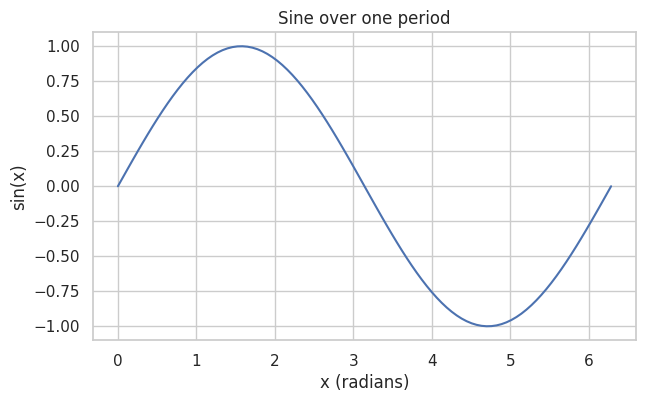

In [25]:
x = np.linspace(0, 2 * np.pi, 100)
y = np.sin(x)

plt.figure(figsize=(7, 4))
plt.plot(x, y)
plt.title("Sine over one period")
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

### 8(b) Several curves on one axes with different styles, a legend, a text annotation and a mathematical expression

The mathematical expression is written in mathtext, the LaTeX subset matplotlib renders between dollar signs, and is placed with annotate() together with an arrow pointing at the curve it describes.

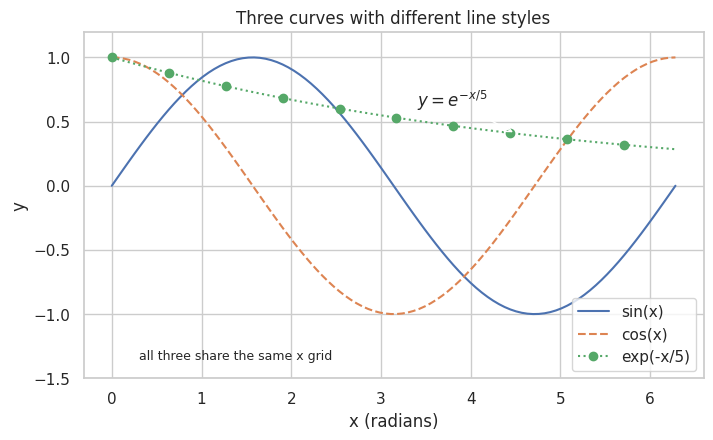

In [26]:
y2 = np.cos(x)
y3 = np.exp(-x / 5)

plt.figure(figsize=(8, 4.5))
plt.plot(x, y, linestyle="-", label="sin(x)")
plt.plot(x, y2, linestyle="--", label="cos(x)")
plt.plot(x, y3, linestyle=":", marker="o", markevery=10, label="exp(-x/5)")

# the band below -1 is kept clear so the text and the legend never sit on a curve
plt.ylim(-1.5, 1.2)
plt.text(0.3, -1.35, "all three share the same x grid", fontsize=9)
plt.annotate("$y = e^{-x/5}$", xy=(4.5, np.exp(-4.5 / 5)), xytext=(3.4, 0.62),
             fontsize=12, arrowprops=dict(arrowstyle="->"))

plt.title("Three curves with different line styles")
plt.xlabel("x (radians)")
plt.ylabel("y")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### 8(c) A figure of several subplots with an explicit figure size and varied font sizes

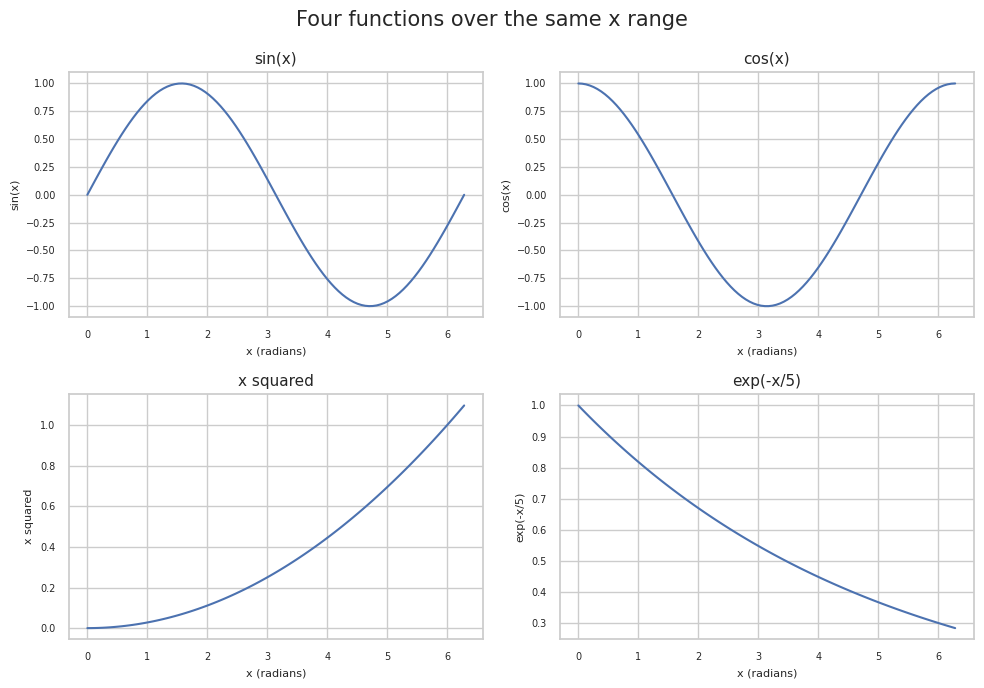

In [27]:
panels = [("sin(x)", np.sin(x)),
          ("cos(x)", np.cos(x)),
          ("x squared", (x / 6) ** 2),
          ("exp(-x/5)", np.exp(-x / 5))]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for panel, (name, values) in zip(axes.flat, panels):
    panel.plot(x, values)
    panel.set_title(name, fontsize=11)
    panel.set_xlabel("x (radians)", fontsize=8)
    panel.set_ylabel(name, fontsize=8)
    panel.tick_params(labelsize=7)

fig.suptitle("Four functions over the same x range", fontsize=15)
fig.tight_layout()
plt.show()

### 8(d) The same kind of plot drawn through the gca() handle

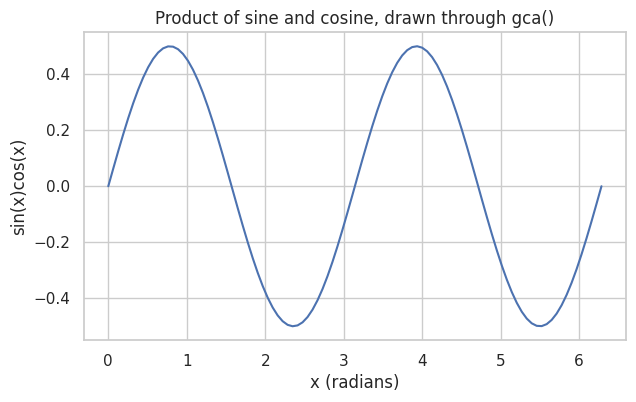

In [28]:
plt.figure(figsize=(7, 4))
panel = plt.gca()
panel.plot(x, np.sin(x) * np.cos(x))
panel.set_title("Product of sine and cosine, drawn through gca()")
panel.set_xlabel("x (radians)")
panel.set_ylabel("sin(x)cos(x)")
panel.grid(True)
plt.show()

gca() returns the Axes object currently active in the current figure, creating one if the figure does not have any yet. Holding that object means the drawing is done by calling methods on the Axes itself, such as set_title and set_xlabel, instead of going through the pyplot functions that act on whatever axes happens to be current.

### 8(e) Explicit axis limits and a logarithmic axis

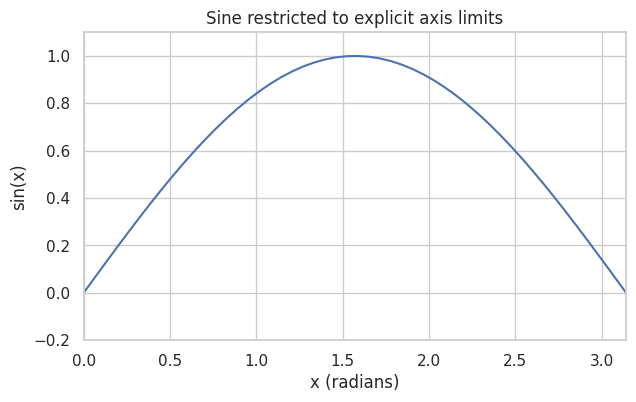

In [29]:
plt.figure(figsize=(7, 4))
plt.plot(x, y)
plt.xlim(0, np.pi)
plt.ylim(-0.2, 1.1)
plt.title("Sine restricted to explicit axis limits")
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

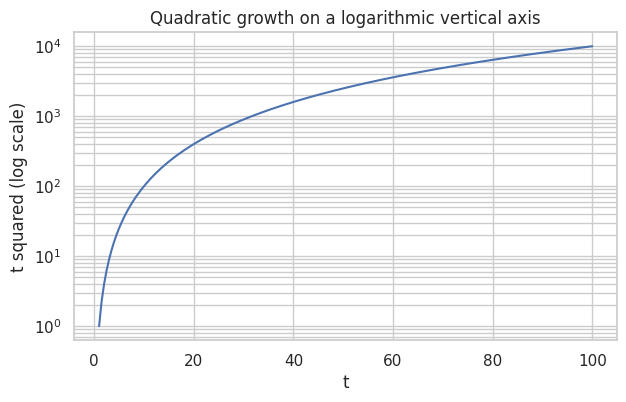

In [30]:
t = np.linspace(1, 100, 200)

plt.figure(figsize=(7, 4))
plt.plot(t, t ** 2)
plt.yscale("log")
plt.title("Quadratic growth on a logarithmic vertical axis")
plt.xlabel("t")
plt.ylabel("t squared (log scale)")
plt.grid(True, which="both")
plt.show()

The first figure still holds the full sine curve but shows only the window set by xlim and ylim, so the drawing stops at x equal to pi. On the second figure the vertical axis is logarithmic, so equal distances up the axis stand for equal ratios rather than equal differences. The quadratic is not a straight line there, because only the vertical axis is logarithmic; it would straighten only if the horizontal axis were logarithmic as well.